# IBM Qiskit Fall Fest 2026  

# Securing Communication in the Quantum Era
### A Hands-on Qiskit Tutorial on Quantum Communication, BB84 and Eavesdropping and Teleporatation

## What will we build?

In this notebook, we will use Qiskit to explore:

1. Quantum communication

       1.a. Quantum Teleportation


*      1.b. Quantum Communication
*             BB84 quantum key distribution
*                      An intercept-and-resend attack by Eve
                       Quantum bit error rate (QBER)
                       The difference between physical noise and eavesdropping

2.  Post-quantum cryptography (PQC)



## Learning objectives

By the end of the tutorial, you should be able to:

- Create and measure quantum circuits with Qiskit.
- Explain the role of different measurement bases.
- Understand the basic idea of quantum teleportation.
- Implement one of the Quantum Key Distribution Protocols - BB84.
- Simulate an intercept-and-resend attack.
- Calculate QBER from experimental data.
- Understand post-quantum cryptography (PQC).

> **Important:** All the experiments are performed on the AER simulator using the Qiskit Framework: No usage of a Quantum Processing Unit (QPU).

# 0. Setup

We will install Qiskit , qiskit-aer for simulation and circuit drawing purpose
and some standard Python libraries for numerical calculations and plots.

In [3]:
!uv pip install -q qiskit-aer
!uv pip install -q "qiskit[visualization]>=2.5.2"
!uv pip install -q pylatexenc


# 1. Imports

In [1]:
#Python utilities
import matplotlib.pyplot as plt
#Qiskit utilities
from qiskit.visualization import plot_histogram
from qiskit import QuantumCircuit, transpile
# Set up the AER simulator Backend
from qiskit_aer import AerSimulator
simulator = AerSimulator()

# 2. Measuring in Different Bases



### Z basis / computational basis

$$
\{|0\rangle, |1\rangle\}
$$

### X basis / Hadamard basis

$$
\{|+\rangle, |−\rangle\}
$$

where

$$
|+\rangle = \frac{|0\rangle+|1\rangle}{\sqrt{2}}
$$

and

$$
|−\rangle = \frac{|0\rangle-|1\rangle}{\sqrt{2}}.
$$

In Qiskit, measurement in the X basis can be implemented by applying a Hadamard gate immediately before measurement.

## Experiment: prepare |+> and measure in the X basis

If we prepare |+> and measure in the X basis, the result should be deterministic: 0.

This basis dependence is one of the key ideas behind BB84.

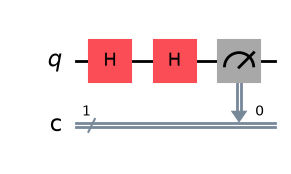

{'0': 1000}


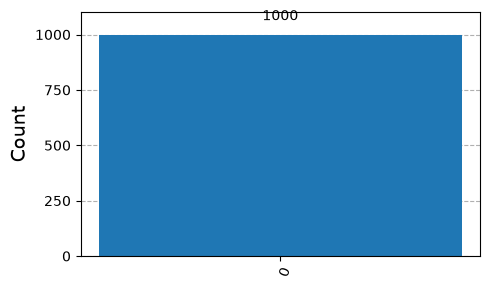

In [2]:
qc = QuantumCircuit(1, 1)

# Prepare |+>
qc.h(0)

# Measure in X basis
qc.h(0)
qc.measure(0, 0)

display(qc.draw('mpl'))

result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()

print(counts)

# Plot the measurement results
plot_histogram(counts, figsize=(5, 3))

#Quantum Entanglement:
* A quantum mechanical phenomenon in which two or more particles (Qubits) are correlated in their global state.
* Measurement of the state of one particle instantaneously influences the state of another particle, regardless of the distance between them.


$$|\Phi^+\rangle_{AB} = \frac{1}{\sqrt{2}}(|0\rangle_A \otimes |0\rangle_B + |1\rangle_A \otimes |1\rangle_B) ,$$

$$|\Psi^+\rangle_{AB} = \frac{1}{\sqrt{2}}(|0\rangle_A \otimes |1\rangle_B + |1\rangle_A \otimes |0\rangle_B),$$

$$|\Psi^-\rangle_{AB} = \frac{1}{\sqrt{2}}(|0\rangle_A \otimes |1\rangle_B - |1\rangle_A \otimes |0\rangle_B),$$

$$|\Phi^-\rangle_{AB} = \frac{1}{\sqrt{2}}(|0\rangle_A \otimes |0\rangle_B - |1\rangle_A \otimes |1\rangle_B),$$



# Create Entanglement pair - Phi+

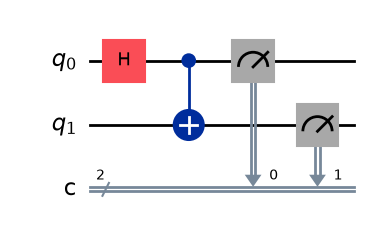

{'00': 487, '11': 513}


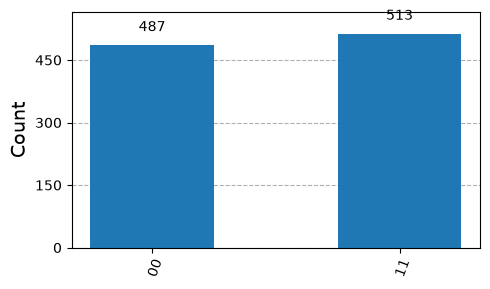

In [3]:

qc1=QuantumCircuit(2, 2)
qc1.h(0)
qc1.cx(0, 1)
qc1.measure([0,1], [0,1])
display(qc1.draw('mpl'))

# run

#result = simulator.run(qc1, shots=1).result()   #shot=1
result= simulator.run(qc1, shots=1000).result() # shot=1000
counts = result.get_counts()

print(counts)

# Plot the measurement results
plot_histogram(counts, figsize=(5, 3))


# 3. Quantum Communication: Teleportation

Quantum teleportation does **not** transport a physical particle from Alice to Bob.

Instead, it transfers an unknown quantum state using:

- a shared entangled pair(Each have a Qubit of the Entangled Pair)
- Bell state Mesurement(BSM)
- two classical bits,
- quantum measurement,
- conditional corrections.

**Two parites should be entangled before teleport any qubit**

Alice side


*   Unknown Qubit that need to be teleport
*   One Entangled Qubit

Bob side
* Another Entangled Qubit

Steps

* 1 - Alice performs BSM on two qubits(Unknown & Entangled)
* 2 - Alice get two classical bits (00/01/10/11) as a BSM measurement result
* 3- Alice send two bits  to the Bob through the classical channel
* 4- According to the recieved infromation ,Bob applies (**I for 00, Z for 01, X for 10, and ZX for 11** ) opertions on her Qubit to recreate the state of the  Unknown Qubit.

*No Qubit is transmitted , only classical bits are transmitted*----------------------------------------------------
*There is no way to intercept the infromation*



    

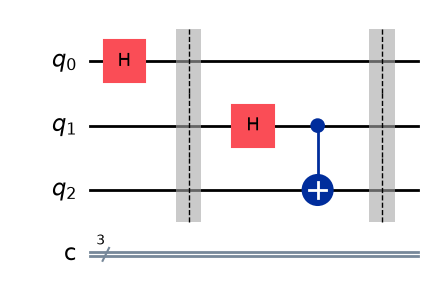

In [4]:
# Qubits:
# q0 = Alice's unknown state
# q1 = Alice's entangled qubit
# q2 = Bob's entangled qubit

qc2 = QuantumCircuit(3, 3)

# Prepare an example unknown state |+>
qc2.h(0)
qc2.barrier()

# Create Bell pair between q1 and q2
qc2.h(1)
qc2.cx(1, 2)
qc2.barrier()
display(qc2.draw('mpl'))


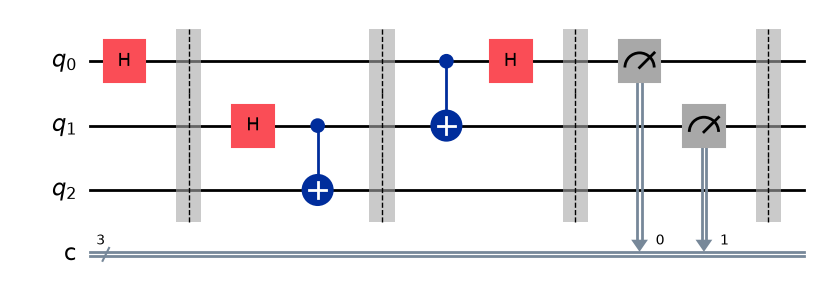

In [5]:
# Alice performs Bell-basis operations(BSM)
qc2.cx(0, 1)
qc2.h(0)
qc2.barrier()

# Alice measures q0 and q1
qc2.measure(0, 0)
qc2.measure(1, 1)
qc2.barrier()

display(qc2.draw('mpl'))

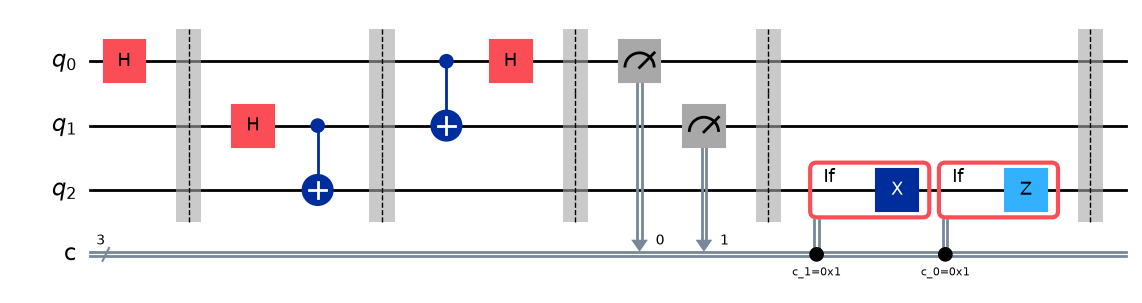

In [6]:
# Conditional corrections on Bob's qubit
# For 00: Neither clbits[1] nor clbits[0] is True. No gates are applied.

#For 01: Only clbits[0] is True. Only the Z gate is applied.

#For 10: Only clbits[1] is True. Only the X gate is applied.

#For 11: Both are True. Both the X gate and Z gate are applied sequentially

with qc2.if_test((qc2.clbits[1], True)):
    qc2.x(2)

with qc2.if_test((qc2.clbits[0], True)):
    qc2.z(2)
qc2.barrier()
display(qc2.draw('mpl'))

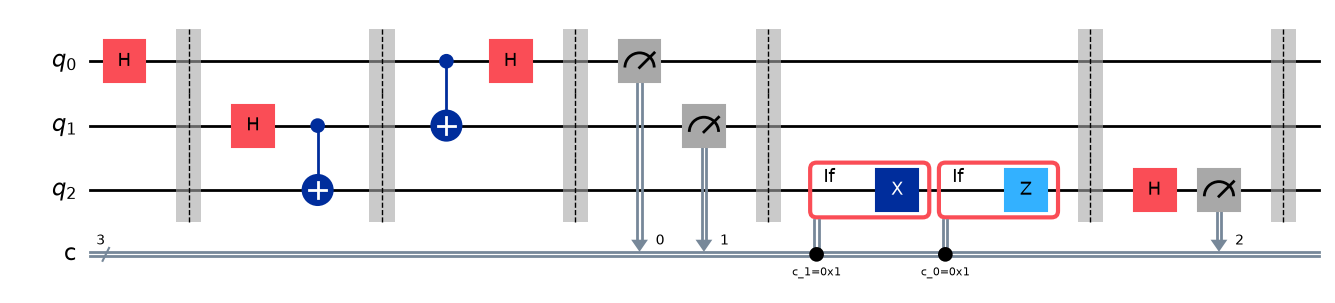

In [7]:

# 6. VERIFICATION STEP
# Apply H to q2 to measure in the X-basis, then measure into c2
qc2.h(2)
qc2.measure(2, 2)
qc2.barrier()

display(qc2.draw('mpl'))



Measurement Counts: {'001': 253, '000': 247, '011': 259, '010': 265}


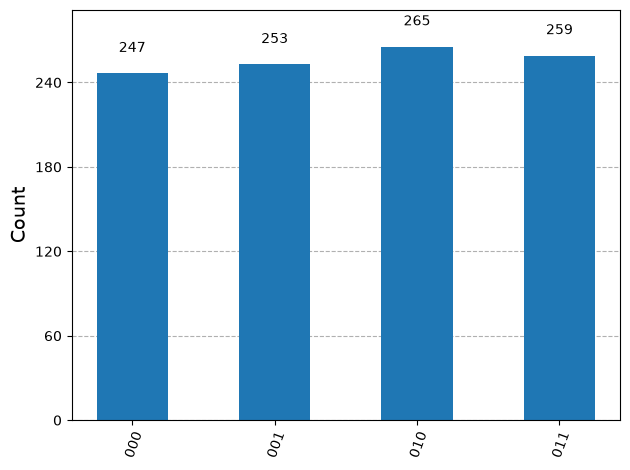

In [13]:
# Run the circuit on the simulator
simulator = AerSimulator()
compiled_circuit = transpile(qc2, simulator)
job = simulator.run(compiled_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement Counts:", counts)
display(plot_histogram(counts))

Qubit 2 only: {'0': 1024}


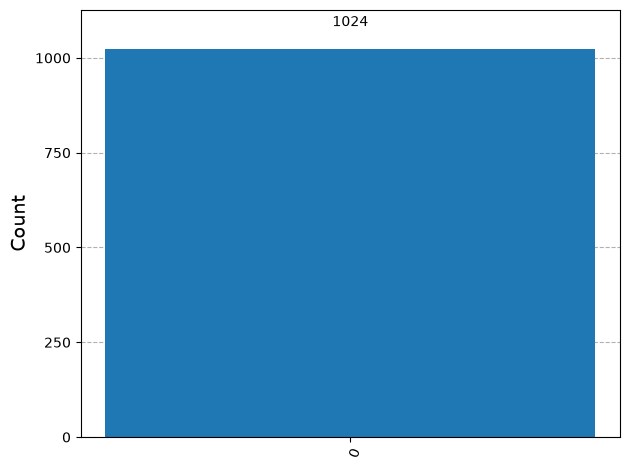

In [16]:
# Extract ONLY the results for index 2 (which is c2, holding q2's measurement)
from qiskit.result import marginal_counts

q2_counts = marginal_counts(counts, indices=[2])

print("Qubit 2 only:", q2_counts)
display(plot_histogram(q2_counts))

# 4. BB84 Quantum Key Distribution

BB84 was proposed by Charles Bennett and Gilles Brassard in 1984.

The basic idea:

- Alice generates random classical bits.
- Alice randomly chooses a basis for every bit.
- Alice encodes each bit as a quantum state.
- Bob randomly chooses a measurement basis.
- Alice and Bob publicly compare only their bases.
- They keep the results where their bases matched.

The retained bits form the **sifted key**.

The security comes from the fact that measuring a quantum state in the wrong basis can disturb the state.

## BB84 encoding

We use:

| Bit | Z basis | X basis |
|---|---|---|
| 0 | $|0\rangle$ | $|+\rangle$ |
| 1 | $|1\rangle$ | $|−\rangle$ |

We represent:

- `basis = 0` → Z basis
- `basis = 1` → X basis

and

- `bit = 0/1`


In [17]:
def encode_qubit(bit, basis):
    qc = QuantumCircuit(1, 1)

    # Encode the bit
    if bit == 1:
        qc.x(0)

    # Prepare X-basis state
    if basis == 1:
        qc.h(0)

    return qc


def measure_qubit(qc, basis):
    # Rotate X-basis state back to Z basis
    if basis == 1:
        qc.h(0)

    qc.measure(0, 0)
    return qc

### Test the Encoder

If Alice and Bob use the **same basis**, Bob should recover Alice's bit in an ideal noiseless simulation.

In [18]:
for bit in [0, 1]:
    for alice_basis in [0, 1]:

        # Alice prepares the qubit
        qc = encode_qubit(bit, alice_basis)

        # Test case: Bob uses the same basis as Alice
        bob_basis = alice_basis
        qc = measure_qubit(qc, bob_basis)

        result = simulator.run(qc, shots=100).result()
        counts = result.get_counts()

        print(
            f"Alice bit={bit}, "
            f"Alice basis={alice_basis}, "
            f"Bob basis={bob_basis}: {counts}"
        )

Alice bit=0, Alice basis=0, Bob basis=0: {'0': 100}
Alice bit=0, Alice basis=1, Bob basis=1: {'0': 100}
Alice bit=1, Alice basis=0, Bob basis=0: {'1': 100}
Alice bit=1, Alice basis=1, Bob basis=1: {'1': 100}


## 5. BB84 Without Eve

We now simulate many transmitted qubits.

For each qubit:

1. Alice randomly chooses a bit and basis.
2. Alice encodes the qubit.
3. Bob randomly chooses a basis and measures.
4. Alice and Bob compare their basis choices.
5. They keep only the matching-basis bits. This forms the **sifted key**.

Total transmitted: 200
Matching bases: 86
Sifted key length: 86
Alice sifted key: [1 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1]
Bob sifted key:   [1 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1]

Full 10-bit Quantum Circuit (Alice Bits: [1 1 1 0 0 0 0], Alice Bases: [0 1 1 1 0 1 1], Bob Bases: [0 1 0 0 1 1 0]):


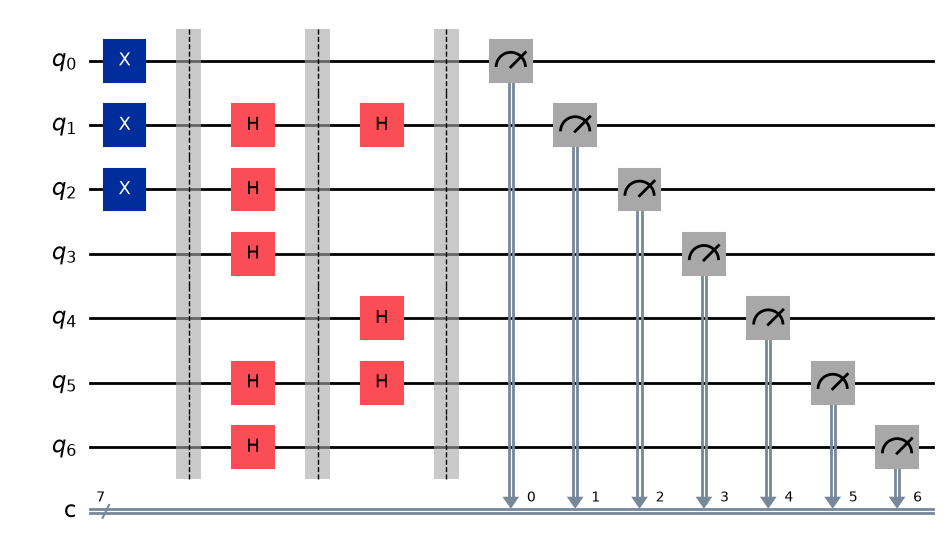

In [19]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Initialize the simulator
simulator = AerSimulator()

def encode_qubit(bit, basis):
    qc = QuantumCircuit(1, 1)
    if bit == 1:
        qc.x(0)
    if basis == 1:
        qc.h(0)
    return qc

def measure_qubit(qc, basis):
    if basis == 1:
        qc.h(0)
    qc.measure(0, 0)
    return qc

def bb84_run(n=100):
    alice_bits = np.random.randint(0, 2, n)
    alice_bases = np.random.randint(0, 2, n)
    bob_bases = np.random.randint(0, 2, n)

    bob_results = []

    for bit, a_basis, b_basis in zip(
        alice_bits, alice_bases, bob_bases
    ):
        qc = encode_qubit(bit, a_basis)
        qc = measure_qubit(qc, b_basis)

        result = simulator.run(qc, shots=1).result()
        measured_bit = int(next(iter(result.get_counts())))

        bob_results.append(measured_bit)

    bob_results = np.array(bob_results)

    matching = alice_bases == bob_bases

    return {
        "alice_bits": alice_bits,
        "alice_bases": alice_bases,
        "bob_bases": bob_bases,
        "bob_results": np.array(bob_results),
        "matching": matching,
        "sifted_alice": alice_bits[matching],
        "sifted_bob": bob_results[matching]
    }


data = bb84_run(200)

print("Total transmitted:", len(data["alice_bits"]))
print("Matching bases:", np.sum(data["matching"]))
print("Sifted key length:", len(data["sifted_alice"]))
print("Alice sifted key:", data["sifted_alice"][:30])
print("Bob sifted key:  ", data["sifted_bob"][:30])

# Construct a single large circuit for 10 bits with clear barriers
n_bits = 7
alice_bits_10 = np.random.randint(0, 2, n_bits)
alice_bases_10 = np.random.randint(0, 2, n_bits)
bob_bases_10 = np.random.randint(0, 2, n_bits)

full_qc = QuantumCircuit(n_bits, n_bits)

# 1. Prepare State / Bit Encoding (X gate if bit is 1)
for i in range(n_bits):
    if alice_bits_10[i] == 1:
        full_qc.x(i)

full_qc.barrier()

# 2. Basis encoding (H gate if diagonal basis)
for i in range(n_bits):
    if alice_bases_10[i] == 1:
        full_qc.h(i)

# Quantum Channel transmission barrier
full_qc.barrier()

# 3. Bob's basis transformation (H gate if diagonal basis)
for i in range(n_bits):
    if bob_bases_10[i] == 1:
        full_qc.h(i)

full_qc.barrier()

# 4. Bob's Measurement
for i in range(n_bits):
    full_qc.measure(i, i)

print(f"\nFull 10-bit Quantum Circuit (Alice Bits: {alice_bits_10}, Alice Bases: {alice_bases_10}, Bob Bases: {bob_bases_10}):")
display(full_qc.draw('mpl'))

### Quantum Bit Error Rate (QBER)

QBER measures the fraction of mismatched bits in the sifted key:

$$QBER = \frac{\text{Number of mismatched bits}} {\text{Length of the sifted key}} \times 100\%$$


In an ideal noiseless simulation without Eve, the QBER should be approximately **0%**.

In [20]:
def qber(alice_key, bob_key):
    if len(alice_key) == 0:
        return np.nan

    return np.mean(alice_key != bob_key)


print(
    "QBER without Eve:",
    qber(data["sifted_alice"], data["sifted_bob"]) * 100,
    "%"
)

QBER without Eve: 0.0 %


### Expected observation

In the ideal simulator, the QBER should be approximately **0** when there is no Eve and no added noise.

The number of sifted bits should be roughly half of the transmitted bits because Alice and Bob independently choose between two bases.

## 6. Introducing Eve: Intercept-and-Resend

Suppose Eve intercepts every qubit sent by Alice.

For each intercepted qubit, Eve:

1. randomly chooses a basis,
2. measures Alice's qubit,
3. prepares a new qubit using her measurement result,
4. sends it to Bob.

Eve does not know Alice's basis.

If Eve chooses the wrong basis, her measurement can disturb the qubit and introduce errors.

### Three Possible Outcomes

After sifting, Alice and Bob keep only the positions where they used the same basis.

For one such sifted bit:

| Scenario | Alice's Basis | Eve's Basis | Bob's Result | Eve Detected? | Probability |
|---|:---:|:---:|---|:---:|:---:|
| 1. Same basis | Z | Z | Correct | ❌ No | **50%** |
| 2. Wrong basis, Bob correct | Z | X | Correct | ❌ No | **25%** |
| 3. Wrong basis, Bob wrong | Z | X | Wrong | ✅ Yes | **25%** |

If Eve chooses the **same basis** as Alice, she measures the qubit correctly and introduces no error.

If Eve chooses the **wrong basis**, her measurement projects the qubit onto the wrong basis. Bob then has a 50% chance of obtaining the correct bit and a 50% chance of obtaining the wrong bit.

Therefore,

$$
P(\text{Eve detected})
=
50\% \times 50\%
=
25\%
$$

and

$$
P(\text{no detectable error})
=
50\% + 25\%
=
75\%
$$

> **Important:** 75% is the probability of no detectable error for **one sifted bit**. It is not the QBER of the complete key.

### Why Does Eve Produce ~25% QBER?

With a full intercept-and-resend attack:

- Eve chooses the wrong basis with probability **50%**.
- When Eve uses the wrong basis, Bob gets the wrong bit with probability **50%**.

Therefore, the expected error probability is:

$$
P(\text{error})
=
50\% \times 50\%
=
25\%
$$

This is the **theoretical expected QBER** for an ideal full intercept-and-resend attack.

The actual QBER is calculated from the simulated sifted keys:

$$
QBER =
\frac{\text{Number of mismatched sifted bits}}
{\text{Length of the sifted key}}
\times 100\%
$$

Because the simulation uses a finite number of qubits, the measured QBER will fluctuate around the theoretical value of **25%**.

In [21]:
def bb84_with_eve(n=1000):
    alice_bits = np.random.randint(0, 2, n)
    alice_bases = np.random.randint(0, 2, n)

    eve_bases = np.random.randint(0, 2, n)
    bob_bases = np.random.randint(0, 2, n)

    eve_results = []
    bob_results = []

    for bit, a_basis, e_basis, b_basis in zip(
        alice_bits, alice_bases, eve_bases, bob_bases
    ):
        # Alice → Eve
        qc_eve = encode_qubit(bit, a_basis)
        qc_eve = measure_qubit(qc_eve, e_basis)

        result_eve = simulator.run(
            qc_eve, shots=1
        ).result()

        eve_bit = int(next(iter(result_eve.get_counts())))
        eve_results.append(eve_bit)

        # Eve → Bob
        qc_bob = encode_qubit(eve_bit, e_basis)
        qc_bob = measure_qubit(qc_bob, b_basis)

        result_bob = simulator.run(
            qc_bob, shots=1
        ).result()

        bob_bit = int(next(iter(result_bob.get_counts())))
        bob_results.append(bob_bit)

    matching = alice_bases == bob_bases

    return {
        "alice_bits": alice_bits,
        "alice_bases": alice_bases,
        "eve_bases": eve_bases,
        "eve_results": np.array(eve_results),
        "bob_bases": bob_bases,
        "bob_results": np.array(bob_results),
        "matching": matching,
        "sifted_alice": alice_bits[matching],
        "sifted_bob": np.array(bob_results)[matching]
    }


eve_data = bb84_with_eve(1000)

print("Transmitted:", len(eve_data["alice_bits"]))
print("Sifted key:", len(eve_data["sifted_alice"]))

print(
    "QBER with intercept-resend Eve:",
    qber(
        eve_data["sifted_alice"],
        eve_data["sifted_bob"]
    ) * 100,
    "%"
)

Transmitted: 1000
Sifted key: 472
QBER with intercept-resend Eve: 23.30508474576271 %


### Probability of Detecting Eve

For one checked sifted bit:

$$
P(\text{no detection}) = 0.75
$$

For \(n\) independently checked sifted bits:

$$
P(\text{no detection}) = (0.75)^n
$$

Therefore,

$$
\boxed{
P(\text{detection}) = 1-(0.75)^n
}
$$

As the number of checked sifted bits increases, the probability of detecting Eve rapidly approaches 100%.

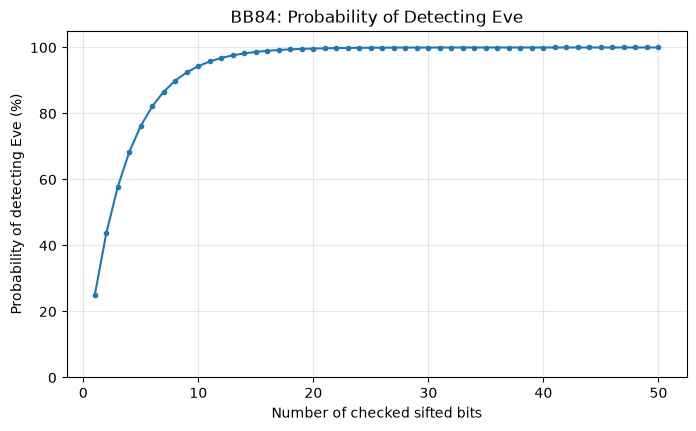

In [22]:
# Probability of detecting Eve vs number of checked sifted bits

n_bits = np.arange(1, 51)
p_detection = 1 - (0.75 ** n_bits)

plt.figure(figsize=(8, 4.5))

plt.plot(
    n_bits,
    p_detection * 100,
    marker="o",
    markersize=3
)

plt.xlabel("Number of checked sifted bits")
plt.ylabel("Probability of detecting Eve (%)")
plt.title("BB84: Probability of Detecting Eve")

plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.show()

### Observation

- **1 bit:** 25% chance of detecting Eve
- **5 bits:** ≈ 76% chance
- **10 bits:** ≈ 94% chance
- **20 bits:** ≈ 99.7% chance
- **50 bits:** ≈ 99.9999% chance

So, although Eve has a **75% chance of escaping detection for an individual checked sifted bit**, checking multiple bits makes detection highly probable.



# 10. From Quantum Cryptography to Post-Quantum Cryptography

There are two ideas that are often confused.

## Quantum cryptography

Quantum cryptography uses **quantum states and quantum mechanics**.

Example:

**BB84**

The security mechanism depends on properties of quantum measurement.

## Post-quantum cryptography (PQC)

PQC uses **classical computers and classical communication networks**.

Its algorithms are designed to resist attacks from sufficiently powerful quantum computers.

Examples include:(The National Institute of Standards and Technology (NIST)  standard)

- **ML-KEM** — a standardized post-quantum key-establishment mechanism
- **ML-DSA** — a standardized post-quantum digital signature scheme

PQC is therefore **not something we need to implement as a Qiskit quantum circuit**.

Qiskit is the right tool in this notebook for demonstrating the quantum side: qubits, quantum states, measurements, BB84 and related protocols.

## Quantum cryptography vs PQC

| Feature | Quantum cryptography | Post-quantum cryptography |
|---|---|---|
| Main example | BB84 | ML-KEM / ML-DSA |
| Uses quantum states? | Yes | No |
| Runs on conventional computers? | Not for the quantum channel itself | Yes |
| Main goal | Quantum-based secure communication | Classical cryptography resistant to quantum attacks |
| Qiskit circuit required? | Yes, for our simulation | No |

### The big picture

A future security architecture may involve both approaches:

**Quantum technologies** for selected quantum communication applications, and  
**PQC** for protecting conventional digital infrastructure against quantum attacks.